# Reviewing the first feature-selection study

Ten inputs produce small, mixed changes relative to all twenty. No model/recipe beats the historical loss-frequency control on Brier score or log loss. This notebook reads a **pinned, completed training-validation study**; it does not select on future observations, train models, search parameters or read the test CSV.

Compare the same four fixed classifiers and thirteen original trading rules using three feature recipes. The [experiment plan](01_experiment_plan.md) specifies all choices, and [the findings](02_findings.md) interpret the results. The app adds interactive model/portfolio controls.

In [1]:
from pathlib import Path
import os
import sys
import json

# Locate the shared project package from either the project or notebook folder.
ROOT = Path.cwd().resolve()
if ROOT.name == "0_3_Feature_Selection":
    ROOT = ROOT.parent
if not (ROOT / "research").is_dir():
    raise RuntimeError("Run from the project root or 0_3_Feature_Selection.")
sys.path.insert(0, str(ROOT))
os.environ["MLFACTOR_READ_ONLY"] = "1"  # Shared fitting functions reject computation.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from research.store import ExperimentStore
from research.feature_studies import load_feature_study, feature_audit

STUDY_ID = "features_20261108T153403_ddfe05c8"
study = load_feature_study(ExperimentStore(), STUDY_ID)
metadata = study["metadata"]
labels = {key: value["label"] for key, value in metadata["recipes"].items()}
display(pd.DataFrame([{"recipe": labels[key], "run_id": value} for key, value in metadata["runs"].items()]))
assert metadata["checks"]["identical_original_returns"]
assert not metadata["checks"]["test_csv_loaded"]

,recipe,run_id
0,All 20 original factors,20261108T153503_eba121c8904e
1,ANOVA top 10,20261108T153555_a41c41a1c46a
2,Correlation-pruned up to 10 (|r| < 0.90),20261108T153648_ce8ca5b600a2


## Compare prediction quality first

Brier score and log loss assess probabilities; lower is better. ROC AUC measures ranking; higher is better, with 0.5 as a no-ranking reference. The historical control uses the realized past loss frequency, with the same timing. These repeated stock-month observations do not support treating tiny score changes as independent statistical evidence.

In [2]:
predictions = study["predictive_comparison"].copy()
control = predictions.loc[predictions.model_id.eq("historical_loss_rate")].iloc[0]
print(f"Historical loss-frequency control: Brier {control.brier_score:.6f}, log loss {control.log_loss:.6f}")
model_rows = predictions.loc[~predictions.model_id.eq("historical_loss_rate")]
comparison = model_rows.pivot(index="model_id", columns="recipe", values="brier_score")
display(comparison[list(labels)].rename(columns=labels).round(6))
display(model_rows[["model_id", "recipe", "brier_score", "log_loss", "roc_auc"]].round(6))
print("Any model beats control on Brier?", bool(model_rows.brier_score.lt(control.brier_score).any()))
print("Any model beats control on log loss?", bool(model_rows.log_loss.lt(control.log_loss).any()))

Historical loss-frequency control: Brier 0.249023, log loss 0.691215


recipe,All 20 original factors,ANOVA top 10,Correlation-pruned up to 10 (|r| < 0.90)
model_id,,,
hist_gradient_boosting,0.249715,0.249683,0.249826
logistic,0.249667,0.249434,0.249507
naive_bayes,0.259759,0.257497,0.254021
random_forest,0.249387,0.249428,0.249548


,model_id,recipe,brier_score,log_loss,roc_auc
0,logistic,all_20,0.249667,0.692578,0.500801
2,naive_bayes,all_20,0.259759,0.714980,0.509354
3,random_forest,all_20,0.249387,0.692021,0.505785
4,hist_gradient_boosting,all_20,0.249715,0.692719,0.507280
5,logistic,anova_10,0.249434,0.692080,0.502109
7,naive_bayes,anova_10,0.257497,0.709745,0.508686
8,random_forest,anova_10,0.249428,0.692101,0.508019
9,hist_gradient_boosting,anova_10,0.249683,0.692632,0.507226
10,logistic,pruned_10,0.249507,0.692236,0.502248
12,naive_bayes,pruned_10,0.254021,0.701998,0.506972


Any model beats control on Brier? False
Any model beats control on log loss? False


## Then compare the same portfolio and model

Change the two names below to inspect another saved case. The original non-ML rule is shown once. The bottom panel measures selected-feature wealth relative to that same model's all-20 wealth. All results are gross of costs and fully invested; the ML overlay changes relative stock weights and does not move money into cash.

,recipe,cagr,sharpe,sortino,max_drawdown,change_cagr_vs_all20
20,all_20,-0.017427,0.030136,0.040229,-0.533461,0.000000
72,anova_10,-0.017410,0.030284,0.040429,-0.533761,0.000017
124,pruned_10,-0.017828,0.028257,0.037707,-0.533581,-0.000400


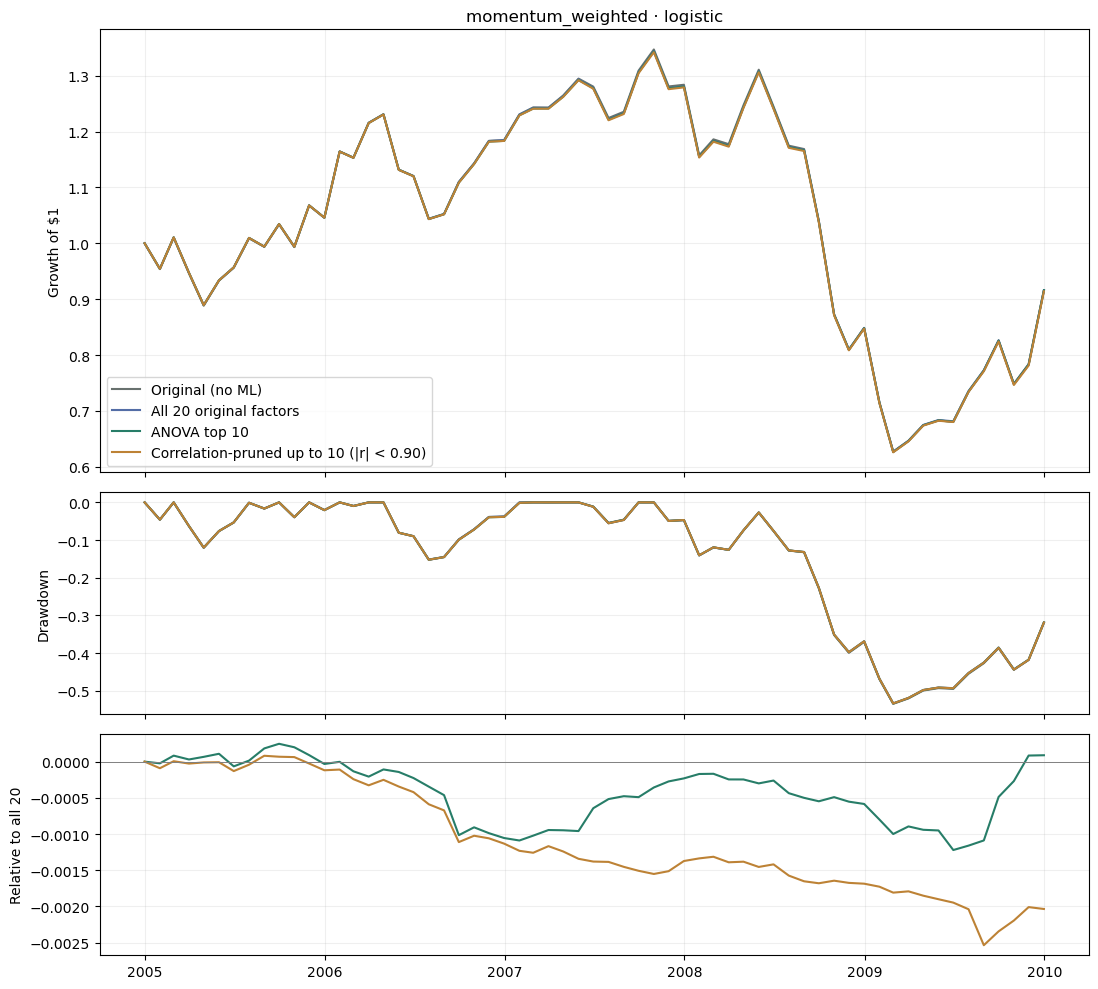

In [3]:
MODEL = "logistic"
STRATEGY = "momentum_weighted"

portfolio = study["portfolio_comparison"]
case_metrics = portfolio.loc[portfolio.model_id.eq(MODEL) & portfolio.strategy.eq(STRATEGY)]
display(case_metrics[["recipe", "cagr", "sharpe", "sortino", "max_drawdown", "change_cagr_vs_all20"]].round(6))

fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True, gridspec_kw={"height_ratios": [2, 1, 1]})
base = study["summaries"]["all_20"]
original_id = base["cases"].loc[lambda x: x.strategy.eq(STRATEGY) & x.variant.eq("baseline"), "case_id"].iloc[0]
original = base["monthly"].loc[lambda x: x.case_id.eq(original_id)].sort_values("return_month")

def draw_path(book, label, color):
    dates = [book.snapshot_date.iloc[0], *book.return_month]
    axes[0].plot(dates, [1, *book.wealth], label=label, color=color)
    axes[1].plot(dates, [0, *book.drawdown], color=color)

# Include the invested dollar before the first return when showing drawdown.
draw_path(original, "Original (no ML)", "#68716e")
reference = None
for (recipe, summary), color in zip(study["summaries"].items(), ["#536da6", "#277d68", "#bd8235"]):
    case_id = summary["cases"].loc[lambda x: x.strategy.eq(STRATEGY) & x.model_id.eq(MODEL), "case_id"].iloc[0]
    book = summary["monthly"].loc[lambda x: x.case_id.eq(case_id)].sort_values("return_month")
    draw_path(book, labels[recipe], color)
    if recipe == "all_20":
        reference = book.wealth.to_numpy()
    else:
        axes[2].plot([book.snapshot_date.iloc[0], *book.return_month], [0, *(book.wealth.to_numpy()/reference - 1)], label=labels[recipe], color=color)
axes[0].set(title=f"{STRATEGY} · {MODEL}", ylabel="Growth of $1")
axes[0].legend(loc="best")
axes[1].set_ylabel("Drawdown")
axes[2].set_ylabel("Relative to all 20")
axes[2].axhline(0, color="gray", linewidth=.7)
for ax in axes:
    ax.grid(alpha=.2)
fig.tight_layout()
plt.show()

## Selection stability and explanations

Selectors were fitted before scaling on each historical training slice. Four models receive the same recipe's mask at the same origin. Both learned methods retained ten factors at every fit. The names can change annually; their union is not a single final ten-factor list. A frozen submission fit would select once before evaluation.

,unique_names_across_annual_fits
recipe,
anova_10,12
pruned_10,11


,recipe,fit_snapshot,trained_through_return_month,training_rows,n_features
20,anova_10,2004-12-31,2004-12-31,69108,10
21,anova_10,2005-12-31,2005-12-31,83439,10
22,anova_10,2006-12-31,2006-12-31,97788,10
23,anova_10,2007-12-31,2007-12-31,112113,10
24,anova_10,2008-12-31,2008-12-31,126417,10
40,pruned_10,2004-12-31,2004-12-31,69108,10
41,pruned_10,2005-12-31,2005-12-31,83439,10
42,pruned_10,2006-12-31,2006-12-31,97788,10
43,pruned_10,2007-12-31,2007-12-31,112113,10
44,pruned_10,2008-12-31,2008-12-31,126417,10


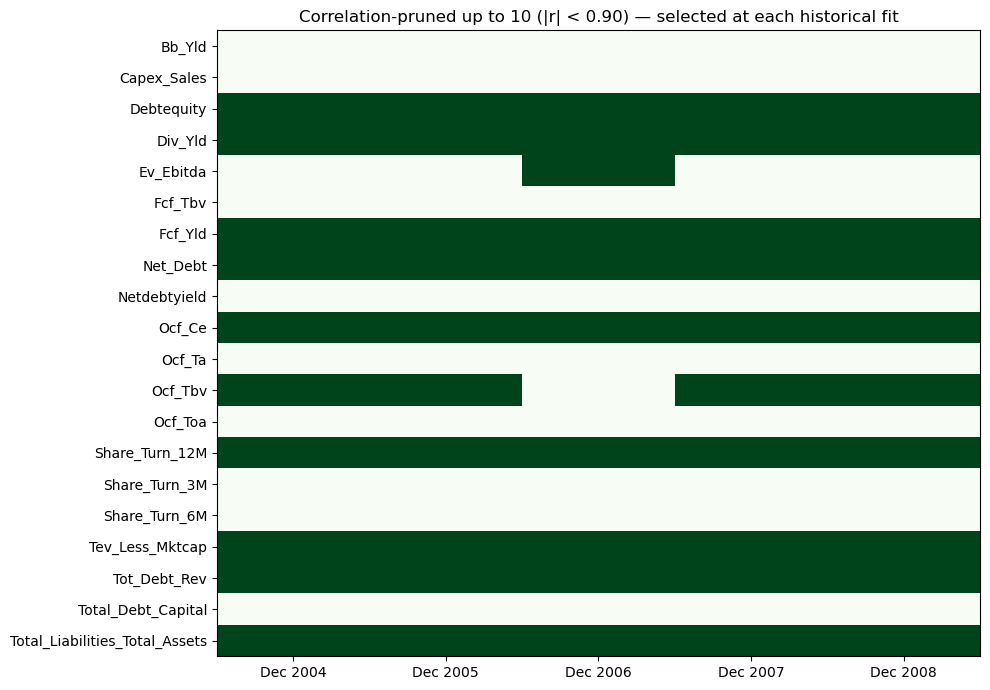

In [4]:
fits = study["fits"]
selected_fits = fits.loc[~fits.recipe.eq("all_20")]
assert selected_fits.n_features.le(10).all()
assert selected_fits.groupby(["recipe", "fit_snapshot"]).fitted_features.nunique().eq(1).all()
audit = feature_audit(selected_fits)
counts = audit.loc[audit.selected & audit.model_id.eq(MODEL)].groupby("recipe").feature.nunique().rename("unique_names_across_annual_fits")
display(counts.to_frame())
display(selected_fits.loc[selected_fits.model_id.eq(MODEL), ["recipe", "fit_snapshot", "trained_through_return_month", "training_rows", "n_features"]])

RECIPE = "correlation_pruned"  # Selector's configuration name; saved recipe key below.
recipe_key = "pruned_10" if RECIPE == "correlation_pruned" else "anova_10"
rows = audit.loc[audit.model_id.eq(MODEL) & audit.recipe.eq(recipe_key)]
history = rows.pivot(index="feature", columns="fit_snapshot", values="selected").astype(int)
fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(history.to_numpy(), aspect="auto", cmap="Greens", vmin=0, vmax=1)
ax.set_xticks(range(len(history.columns)), [f"{date:%b %Y}" for date in history.columns])
ax.set_yticks(range(len(history.index)), history.index)
ax.set_title(labels[recipe_key] + " — selected at each historical fit")
fig.tight_layout()
plt.show()

,feature,score,rank,selected,reason,correlated_with,absolute_correlation
400,Share_Turn_12M,146.845982,1,True,selected,,0.000000
401,Div_Yld,141.024701,2,True,selected,,0.000000
402,Share_Turn_6M,135.519029,3,False,correlated with a higher-ranked selected factor,Share_Turn_12M,0.976732
403,Share_Turn_3M,122.197558,4,False,correlated with a higher-ranked selected factor,Share_Turn_12M,0.948037
404,Ocf_Ce,85.078658,5,True,selected,,0.000000
405,Tot_Debt_Rev,84.716061,6,True,selected,,0.000000
406,Tev_Less_Mktcap,74.057071,7,True,selected,,0.000000
407,Debtequity,67.225031,8,True,selected,,0.000000
408,Total_Debt_Capital,66.524582,9,False,correlated with a higher-ranked selected factor,Debtequity,0.971131
409,Fcf_Yld,61.302571,10,True,selected,,0.000000


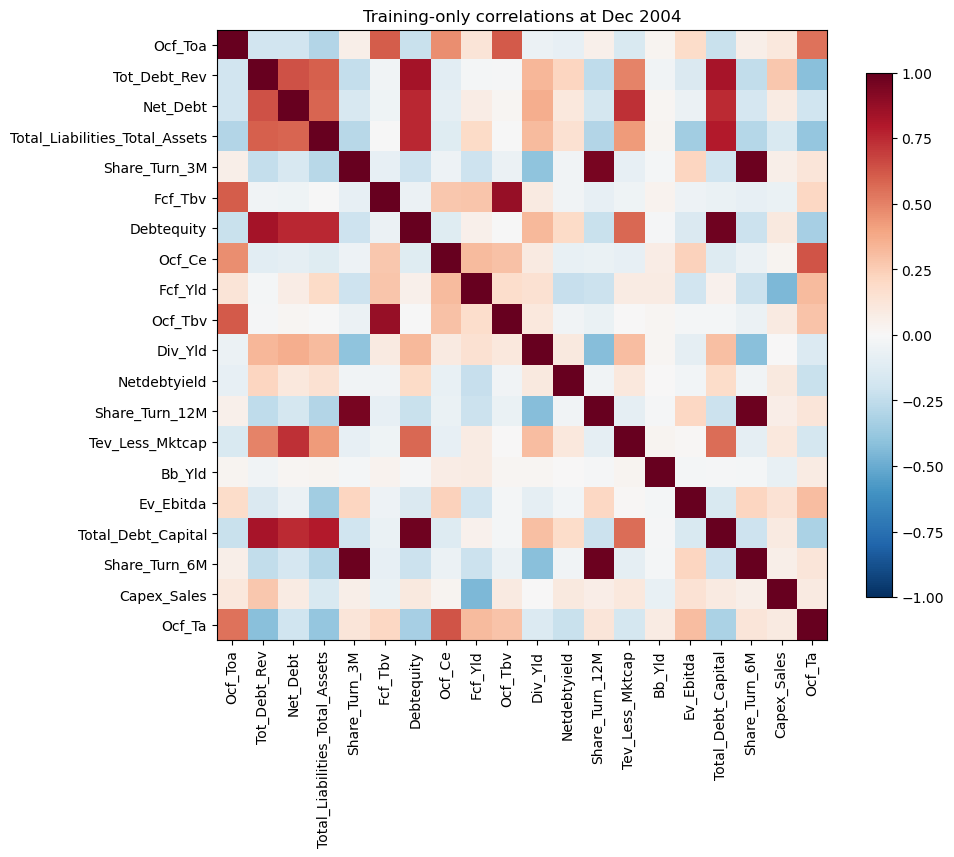

In [5]:
FIT_DATE = rows.fit_snapshot.min()  # Change to another recorded fit date.
fit_audit = rows.loc[rows.fit_snapshot.eq(FIT_DATE)].sort_values("rank")
display(fit_audit[["feature", "score", "rank", "selected", "reason", "correlated_with", "absolute_correlation"]])
fit = fits.loc[fits.model_id.eq(MODEL) & fits.recipe.eq(recipe_key) & fits.fit_snapshot.eq(FIT_DATE)].iloc[0]
correlation = json.loads(fit.training_correlations)
fig, ax = plt.subplots(figsize=(10, 9))
image = ax.imshow(correlation["values"], cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation["columns"])), correlation["columns"], rotation=90)
ax.set_yticks(range(len(correlation["columns"])), correlation["columns"])
ax.set_title(f"Training-only correlations at {FIT_DATE:%b %Y}")
fig.colorbar(image, ax=ax, shrink=.75)
fig.tight_layout()
plt.show()

## Interpretation and next step

ANOVA slightly improves logistic probability scores; removing correlated inputs helps naive Bayes' calibration more. Portfolio gains vary by trading rule and model. None of these results establishes a clear winner or beats the historical probability control on Brier/log loss.

Review the interactive app before choosing the next recipe. Next comes a small, predeclared training-only GridSearchCV experiment, fitting selection inside every chronological inner fold. There is no hyperparameter search or official frozen test result in this study. The existing submission release remains pinned to its earlier draft.